In [4]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

In [9]:
def f(A, b, x):
    return 0.5 * x.T @ A @ x + b.T @ x

def grad_f(A, b, x):
    return A @ x + b

def gd(A, b, x, lr, eps=1e-6):
    I = 0
    while np.linalg.norm(grad_f(A, b, x)) > eps:
        x = x - lr * grad_f(A, b, x)
        I += 1

    return x, I

In [25]:
n = 10

def show_func(n, ax):
    kappa = np.arange(1, 10)
    its = []
    for k in kappa:
        a_diag = np.random.uniform(1, k, n)
        a_diag[0] = 1
        a_diag[-1] = k
        A = np.diag(a_diag)
        b = np.random.uniform(1, k, n)
        x_start = np.zeros(n)

        x, it = gd(A, b, x_start, 1 / k)
        its.append(it)
    ax.plot(kappa, its)
    ax.set_title(f"n: {n}")
    ax.grid()

1604

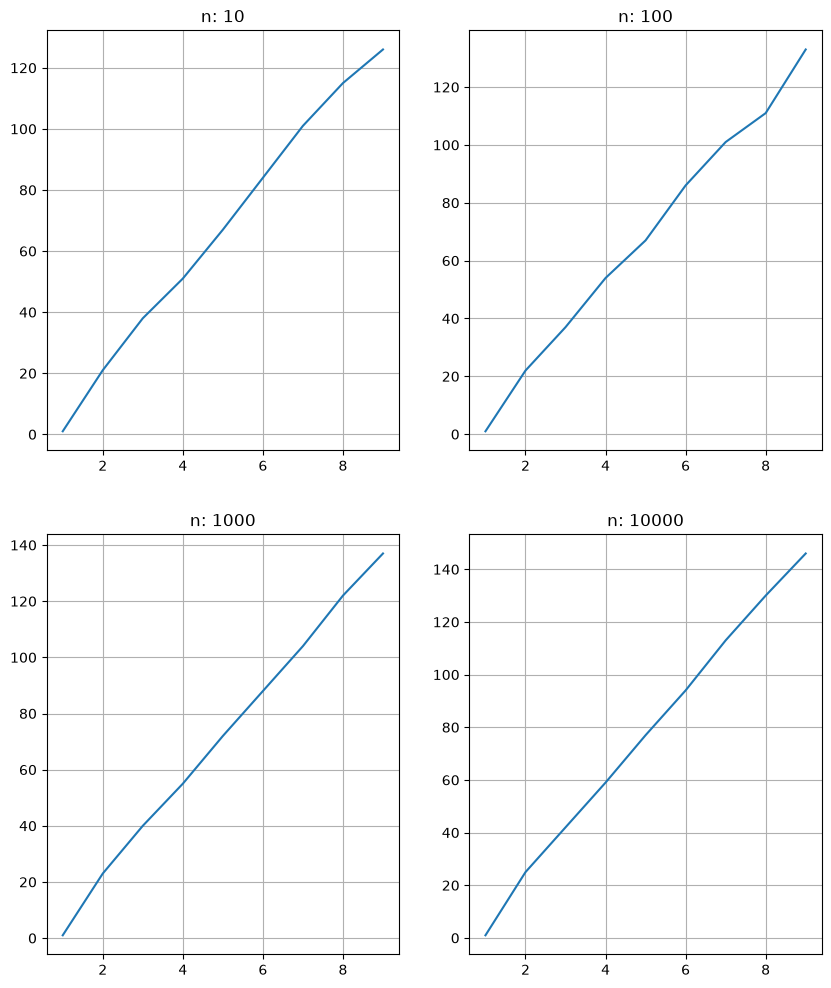

In [27]:
figs, axes = plt.subplots(2, 2, figsize=(10, 12))
ns = [10, 100, 1000, 10000]
show_func(ns[0], axes[0][0])
show_func(ns[1], axes[0][1])
show_func(ns[2], axes[1][0])
show_func(ns[3], axes[1][1])